# Caracterización Interactiva y Extracción .OP de Transistores Sky130 (Std y LVT)
---
Este cuaderno realiza la caracterización analógica completa y extracción del punto de operación (.OP) para los 4 transistores clave del proceso Sky130 (`Mplvt`, `Mp`, `Mnlvt`, `Mn`), utilizando el lector nativo en Python estándar de archivos RAW ASCII de NGspice:

1. **Simulación Dinámica en NGspice y Lector Nativo en Python Estándar (`read_ngspice_raw_ascii`):**
   - Actualización de parámetros geométricos ($W, L, \text{nf}, \text{mult}$) y tensiones de polarización ($V_{SG}, V_{GS}$) directamente desde Python.
   - Ejecución en batch de NGspice y carga directa sin librerías externas mediante `read_ngspice_raw_ascii()`.

2. **Extracción Completa de la Tabla de Punto de Operación (.OP):**
   - Cálculo de corriente total ($I_{D,\text{total}}$), capacitancia total ($C_{gg,\text{total}}$), transconductancia total ($g_{m,\text{total}}$), resistencia de salida ($r_o$) y frecuencia de transición ($f_T$).
   - Verificación estricta de las regiones de **Inversión** (Débil, Moderada, Fuerte según $\Delta_{ov} = V_{gs} - V_{th}$) y **Operación** (Saturación o Triodo según $\Delta_{vd} = V_{ds} - V_{dsat}$).

3. **Curvas de Caracterización Analógica Interactivas en Plotly:**
   - Subgráficos de $I_{D,\text{total}}$, $g_m/I_D$, $f_T$, $r_o$ y $V_{dsat}$ vs $V_{SG}$ (PMOS) y $V_{GS}$ (NMOS) con escala logarítmica explícita para resistencia de salida.


In [1]:
import site
import sys
import subprocess



# 1. Registrar la ruta de paquetes del usuario en el sistema
user_site = '/headless/.local/lib/python3.12/site-packages'
site.addsitedir(user_site)

# 2. Intentar importar; si falla, instalarlo automáticamente
try:
    from PyLTSpice import RawRead
    print("¡PyLTSpice ya estaba instalado y listo para usar!")
except ImportError:
    print("PyLTSpice no fue encontrado. Instalando automáticamente...")
    
    # Ejecuta pip install dentro del mismo Kernel de Python
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--user", "PyLTSpice"])
    
    # Re-asegurar que la ruta esté cargada
    site.addsitedir(user_site)
    
    # Importación tras la instalación
    from PyLTSpice import RawRead
    print("¡PyLTSpice se instaló e importó correctamente!")

¡PyLTSpice ya estaba instalado y listo para usar!


In [2]:
print(40.1*2.4/32.52)
gm_id_11=11.35
id=463.89/gm_id_11
print(id)
print(2.4*8)
print('%%%%%%%%%%%%%%%%%%%%%%%%%%%%%')
gm_id_11=8.27
id=261.53/gm_id_11
print(id)
print(2.4*8)

2.9594095940959404
40.87136563876652
19.2
%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
31.623941958887542
19.2


In [3]:
import subprocess
from PyLTSpice import RawRead
import time
import os 
import subprocess
import re

# 1. Definir las rutas (reemplaza con tus directorios exactos)
netlist = "/headless/.xschem/simulations/caracterizador.spice"
raw_path = "/foss/designs/LDO-sky130/xschem/spice_raw_log/raw/"

mis_parametros = {
    'Mplvt': {'W': 1000, 'L': 0.35, 'nf': 200, 'mult': 1},
    'Mp':    {'W': 28,  'L': 1,  'nf': 1,  'mult': 1},
    'Mnlvt': {'W': 1,   'L': 1, 'nf': 1,  'mult': 1},
    'Mn':    {'W': 40,   'L': 1, 'nf': 1,  'mult': 1},
    'globales': {
        'vsg': 0.6,   # Cambia el .param vsg = ...
        'vgs': 0.85   # Cambia el .param vgs = ...
    }
}

def run_simulation(netlist_path,raw_pad,parametros):
    # 2. Configurar y ejecutar el comando de Ngspice
    # -b: Ejecuta en modo batch (sin interfaz gráfica)
    # -r: Define el archivo de salida raw
    # -o: Define el archivo log para atrapar errores de convergencia o sintaxis
# leer el netlist original
    with open(netlist_path, 'r', encoding='utf-8', errors='ignore') as archivo:
        contenido = archivo.read()

    #print(f"Netlist cargado, tiene {len(contenido)} caracteres.")

    # Iteramos sobre cada transistor en tu diccionario
    for llave, parametros_internos in parametros.items():
        if llave == 'globales':
        
        # Iteramos sobre los parámetros de ese transistor (W, L, nf, mult)
            for parametro, nuevo_valor in parametros_internos.items():
                
                for parametro, nuevo_valor in parametros_internos.items():
                
               
                    patron = rf"(\.param\s+{parametro}\s*=\s*)([-\d\.]+)"
                    
                    # Reemplaza el número viejo por el nuevo
                    contenido = re.sub(patron, rf"\g<1>{nuevo_valor}", contenido, flags=re.IGNORECASE)
                
               

        else:
            for parametro, nuevo_valor in parametros_internos.items():
             # MAGIA: Creamos un patrón de búsqueda dinámico
               # ==========================================================================
                # 1. CONSTRUCCIÓN DEL PATRÓN DE BÚSQUEDA (REGEX)
                # ==========================================================================
                # rf"..." -> 'r' (raw string) para que Python lea los '\' literalmente. 
                #            'f' (f-string) para inyectar variables con { }.
                # 
                # GRUPO 1: (X{nombre_trans}\b.*?{parametro}=) -> Atrapa el texto ANTES del número
                #   - X              : Busca la letra 'X' inicial del transistor.
                #   - {nombre_trans} : Inyecta el nombre (ej. 'Mplvt').
                #   - \b             : Límite de palabra. Evita que al buscar 'Mp' lea 'Mplvt' por error.
                #   - .*?            : '.' (cualquier carácter), '*' (infinitas veces), '?' (detente en la primera coincidencia).
                #   - {parametro}=   : Inyecta el parámetro buscado (ej. 'W=').
                # 
                # GRUPO 2: ([\d\.]+) -> Atrapa el NÚMERO VIEJO (que queremos sobreescribir)
                #   - [ ]            : Conjunto de caracteres permitidos.
                #   - \d             : Cualquier dígito numérico (0-9).
                #   - \.             : Un punto decimal literal.
                #   - +              : Exige que haya 1 o más de estos caracteres (ej. '0.35' o '10').
                
                patron = rf"(X{llave}\b.*?{parametro}=)([\d\.]+)"
                
                # ==========================================================================
                # 2. REEMPLAZO DEL TEXTO
                # ==========================================================================
                # re.sub(patron_a_buscar, texto_de_reemplazo, texto_original, opciones)
                # 
                # - rf"\g<1>{nuevo_valor}" : La estructura del reemplazo.
                #   - \g<1>        : Pega intacto todo lo que atrapó el GRUPO 1 (ej. "XMplvt ... W=").
                #   - {nuevo_valor}: Pega el número nuevo de tu diccionario. 
                #                    (Como nunca llamamos al Grupo 2, el número viejo desaparece).
                # - flags=re.IGNORECASE    : Ignora mayúsculas/minúsculas (W= y w= funcionarán igual).
                
                contenido = re.sub(patron, rf"\g<1>{nuevo_valor}", contenido, flags=re.IGNORECASE)
            
            
                
    # ==========================================================================
    # 3. CREAR EL ARCHIVO TEMPORAL
    # ==========================================================================
    
    # Extrae solo la ruta de la carpeta donde vive tu netlist original (ignora el nombre del archivo).
    directorio_original = os.path.dirname(netlist_path)
    
    # Crea la ruta completa para un archivo nuevo temporal llamado "temp_caracterizador.spice".
    netlist_temp_path = os.path.join(directorio_original, "temp_caracterizador.spice")
    
    # Abre (o crea) este nuevo archivo temporal en modo escritura ('w' de write).
    with open(netlist_temp_path, 'w') as archivo_temp:
        # Escribe todo el texto modificado (con los nuevos W y L) dentro del archivo temporal.
        archivo_temp.write(contenido)

    # ==========================================================================
    # 4. SIMULAR CON NGSPICE
    # ==========================================================================
    
    # Prepara la lista de palabras para el comando de terminal que ejecutará Ngspice.
    comando = ['/foss/tools/ngspice/bin/ngspice', "-b", netlist_temp_path]
    
    # Ejecuta el comando en la terminal, atrapa los textos generados y se ubica en la carpeta del diseño.
    resultado = subprocess.run(comando, capture_output=True, text=True, cwd=raw_path)
    
    # Verifica si Ngspice terminó con un error interno (código diferente de cero).
    if resultado.returncode != 0:
        # Imprime en la pantalla que hubo un error.
        print("⚠️ La simulación falló. Aquí está el error de Ngspice:\n")
        # Imprime el mensaje de error exacto que arrojó Ngspice para que puedas leerlo.
        print(resultado.stderr)
    else:
        # Si el código fue cero, imprime un mensaje de éxito.
        print("¡Simulación terminada con éxito!")

    # ==========================================================================
    # 5. BORRAR EL ARCHIVO TEMPORAL
    # ==========================================================================
    
    # Revisa si el archivo temporal existe físicamente en el disco duro.
    
    os.remove(netlist_temp_path)

    return resultado.stdout
    

mi_log = run_simulation(netlist,raw_path,mis_parametros)



¡Simulación terminada con éxito!


In [4]:
import re


# 2. Crear un diccionario vacío para guardar los datos
parametros = {}

# 3. Expresión regular que busca "cualquier_palabra = numero"
# Soporta decimales (72.8159) y notación científica (1.00669e+06)
patron = r"([a-zA-Z0-9_]+)\s*=\s*([+-]?\d+\.?\d*[eE]?[+-]?\d*)"

# 4. Encontrar todas las coincidencias en el texto de mi_log
coincidencias = re.findall(patron, mi_log)
print(coincidencias)
# 5. Llenar el diccionario convirtiendo el texto a números reales (float)
for nombre, valor in coincidencias:
    # nombre.strip() quita espacios extra por seguridad
    parametros[nombre.strip().lower()] = float(valor)

# eliminamos algunos que no sean importantes 

print(parametros)


[('TEMP', '27.000000'), ('TNOM', '27.000000'), ('TEMP', '27.000000'), ('TNOM', '27.000000')]
{'temp': 27.0, 'tnom': 27.0}


In [5]:
from PyLTSpice import RawRead
import os
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.express as px


# Cargar el archivo .raw
#raw = os.path.join(raw_path,"caracterizador.raw")

#raw_op = RawRead(os.path.join(raw_path,"caracterizador_op.raw"))
"""
# Imprimir la lista de todos los nombres de nodos y ramas guardados
print("Variables disponibles:")
for var in raw_op.get_trace_names():
    print(" -", var)
"""

# Extraer el eje horizontal (Tiempo en .tran, Frecuencia en .ac, Voltaje en .dc)
#id = raw.get_trace("i(@m.xmn.msky130_fd_pr__nfet_01v8[id])").get_wave()
#print(id)
# Extraer voltajes y corrientes de interés
#v_out = raw.get_trace("v(vo)").get_wave()
#i_load = raw.get_trace("i(vsense)").get_wave()
# graficar:
#fig = px.line(x=tiempo, y=v_out, title="Medicion de undershoot y overshoot en el LDO",labels={'x': 'Tiempo [s]', 'y': 'Voltaje de salida [V]'})

'\n# Imprimir la lista de todos los nombres de nodos y ramas guardados\nprint("Variables disponibles:")\nfor var in raw_op.get_trace_names():\n    print(" -", var)\n'

In [6]:
import pandas as pd
import numpy as np
from PyLTSpice import RawRead
import os
import re
from matplotlib.ticker import EngFormatter  # La librería mágica

def generar_tabla_inteligente_op(ruta_raw):
    """
    Lee un archivo OP, agrupa los datos por transistor, filtra la basura,
    y calcula ro, gm/Id y fT automáticamente.
    """
    if not os.path.exists(ruta_raw):
        print(f"⚠️ El archivo no existe: {ruta_raw}")
        return None
        
    try:
        raw_op = RawRead(ruta_raw)
    except Exception as e:
        print(f"⚠️ Error al leer el archivo RAW: {e}")
        return None

    variables = raw_op.get_trace_names()
    datos_agrupados = {}

    patron = r"x([a-zA-Z0-9_]+)\.msky130.*?\[([a-zA-Z0-9_]+)\]"

    for var in variables:
        match = re.search(patron, var, re.IGNORECASE)
        if match:
            transistor = match.group(1).upper() 
            parametro = match.group(2).lower()  
            
            wave = raw_op.get_trace(var).get_wave()
            if len(wave) > 0:
                valor = float(np.real(wave[0]))
                
                if parametro in ['id', 'vgs', 'vth', 'vdsat']:
                    valor = abs(valor)
                    
                if transistor not in datos_agrupados:
                    datos_agrupados[transistor] = {}
                    
                datos_agrupados[transistor][parametro] = valor

    # ==============================================================================
    # CÁLCULOS INTELIGENTES
    # ==============================================================================
    for t, params in datos_agrupados.items():
        if 'gds' in params and params['gds'] != 0:
            params['ro'] = 1 / params['gds']
            
        if 'gm' in params and 'id' in params and params['id'] != 0:
            params['gm/id'] = params['gm'] / params['id']
            
        if 'gm' in params and 'cgg' in params and params['cgg'] != 0:
            # EL ÚNICO CAMBIO: Le quitamos el "/ 1e9" para que la librería ponga la 'G' sola
            params['ft'] = params['gm'] / (2 * np.pi * params['cgg'])

    df = pd.DataFrame.from_dict(datos_agrupados, orient='index')
    
    # Le quitamos el (GHz) al nombre de la columna
    columnas_ideales = ['id', 'vgs', 'vth', 'vdsat', 'gm', 'ro', 'gm/id', 'cgg', 'ft']
    columnas_finales = [c for c in columnas_ideales if c in df.columns]
    df = df[columnas_finales]
    
    return df

# ==============================================================================
# EJEMPLO DE USO:
# ==============================================================================
ruta_op = os.path.join(raw_path, "caracterizador_op.raw")
tabla_resultados = generar_tabla_inteligente_op(ruta_op)

# Creamos la máscara visual (places=2 son los decimales)
formateador_si = EngFormatter(places=2)

# Se la aplicamos a la tabla de Pandas
tabla_bonita = tabla_resultados.style.format(lambda x: formateador_si(x) if pd.notna(x) else "-")

display(tabla_bonita)

,id,vgs,vth,vdsat,gm,ro,gm/id,cgg,ft
MN,458.65 µ,849.87 m,557.86 m,238.83 m,2.93 m,69.05 k,6.39,227.04 f,2.06 G
MNLVT,16.80 µ,850.00 m,494.09 m,292.83 m,84.22 µ,894.60 k,5.01,5.33 f,2.51 G
MP,439.52 p,600.00 m,1.03,42.47 m,12.76 n,71.71 G,29.04,56.64 f,35.86 k
MPLVT,10.39 m,599.98 m,336.08 m,253.80 m,57.85 m,302.26,5.57,1.83 p,5.02 G


Cargando vectores, por favor espera...


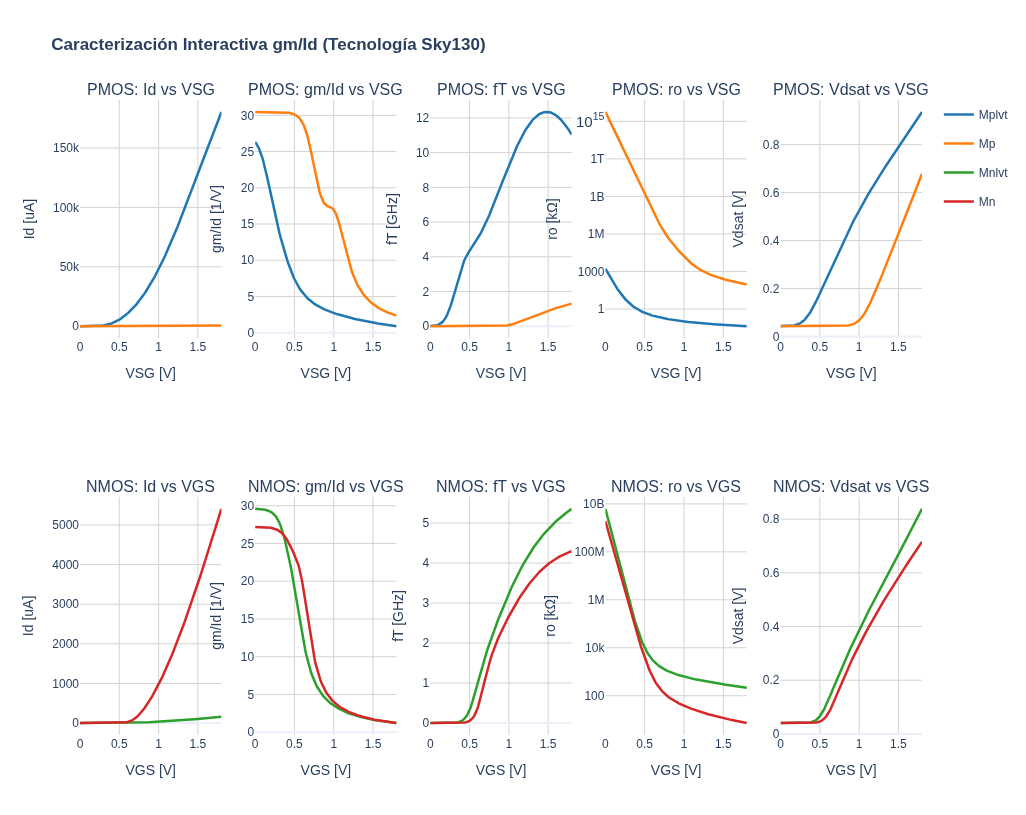

In [7]:
import os
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from PyLTSpice import RawRead

# ==============================================================================
# 1. CARGAR EL ARCHIVO RAW (.dc)
# ==============================================================================
raw_path = "/foss/designs/LDO-sky130/xschem/spice_raw_log/raw/"
# Leemos el archivo donde están los barridos (no el .op)
ruta_raw_dc = os.path.join(raw_path, "caracterizador.raw") 

print("Cargando vectores, por favor espera...")
raw_data = RawRead(ruta_raw_dc)

# ==============================================================================
# 2. DEFINIR ESTRUCTURA DE TRANSISTORES (Compatible con PyLTSpice)
# ==============================================================================
transistores = {
    'Mplvt': {
        'tipo': 'PMOS', 'mult': 1,
        'vgs': 'v(@m.xmplvt.msky130_fd_pr__pfet_01v8_lvt[vgs])',
        'id': 'i(@m.xmplvt.msky130_fd_pr__pfet_01v8_lvt[id])',
        'gm': '@m.xmplvt.msky130_fd_pr__pfet_01v8_lvt[gm]',
        'gds': '@m.xmplvt.msky130_fd_pr__pfet_01v8_lvt[gds]',
        'vdsat': 'v(@m.xmplvt.msky130_fd_pr__pfet_01v8_lvt[vdsat])',
        'cgg': '@m.xmplvt.msky130_fd_pr__pfet_01v8_lvt[cgg]'
    },
    'Mp': {
        'tipo': 'PMOS', 'mult': 1,
        'vgs': 'v(@m.xmp.msky130_fd_pr__pfet_01v8[vgs])',
        'id': 'i(@m.xmp.msky130_fd_pr__pfet_01v8[id])',
        'gm': '@m.xmp.msky130_fd_pr__pfet_01v8[gm]',
        'gds': '@m.xmp.msky130_fd_pr__pfet_01v8[gds]',
        'vdsat': 'v(@m.xmp.msky130_fd_pr__pfet_01v8[vdsat])',
        'cgg': '@m.xmp.msky130_fd_pr__pfet_01v8[cgg]'
    },
    'Mnlvt': {
        'tipo': 'NMOS', 'mult': 1,
        'vgs': 'v(@m.xmnlvt.msky130_fd_pr__nfet_01v8_lvt[vgs])',
        'id': 'i(@m.xmnlvt.msky130_fd_pr__nfet_01v8_lvt[id])',
        'gm': '@m.xmnlvt.msky130_fd_pr__nfet_01v8_lvt[gm]',
        'gds': '@m.xmnlvt.msky130_fd_pr__nfet_01v8_lvt[gds]',
        'vdsat': 'v(@m.xmnlvt.msky130_fd_pr__nfet_01v8_lvt[vdsat])',
        'cgg': '@m.xmnlvt.msky130_fd_pr__nfet_01v8_lvt[cgg]'
    },
    'Mn': {
        'tipo': 'NMOS', 'mult': 1,
        'vgs': 'v(@m.xmn.msky130_fd_pr__nfet_01v8[vgs])',
        'id': 'i(@m.xmn.msky130_fd_pr__nfet_01v8[id])',
        'gm': '@m.xmn.msky130_fd_pr__nfet_01v8[gm]',
        'gds': '@m.xmn.msky130_fd_pr__nfet_01v8[gds]',
        'vdsat': 'v(@m.xmn.msky130_fd_pr__nfet_01v8[vdsat])',
        'cgg': '@m.xmn.msky130_fd_pr__nfet_01v8[cgg]'
    }
}

# ==============================================================================
# 3. CONSTRUCCIÓN DE LA INTERFAZ PLOTLY
# ==============================================================================
fig = make_subplots(
    rows=2, cols=5,
    subplot_titles=(
        "PMOS: Id vs VSG", "PMOS: gm/Id vs VSG", "PMOS: fT vs VSG", "PMOS: ro vs VSG", "PMOS: Vdsat vs VSG",
        "NMOS: Id vs VGS", "NMOS: gm/Id vs VGS", "NMOS: fT vs VGS", "NMOS: ro vs VGS", "NMOS: Vdsat vs VGS"
    )
)

colores = {'Mplvt': '#1f77b4', 'Mp': '#ff7f0e', 'Mnlvt': '#2ca02c', 'Mn': '#d62728'}

for nombre, info in transistores.items():
    m_factor = info['mult']
    
    try:
        # Extraemos la onda completa de voltaje primero
        vgs_full = np.real(np.abs(raw_data.get_trace(info['vgs']).get_wave()))
        
        # Filtro inteligente (Slice automático): 
        # Toma solo los índices de los voltajes únicos y ordenados
        _, s = np.unique(vgs_full, return_index=True)
        
        # Aplicamos este filtro a todos los vectores para aislar la curva perfecta
        vgs = vgs_full[s]
        id_tot = np.real(np.abs(raw_data.get_trace(info['id']).get_wave()))[s] * m_factor * 1e6  # uA
        gm = np.real(np.abs(raw_data.get_trace(info['gm']).get_wave()))[s]
        gds = np.real(np.abs(raw_data.get_trace(info['gds']).get_wave()))[s]
        vdsat = np.real(raw_data.get_trace(info['vdsat']).get_wave())[s]
        cgg_u = np.real(np.abs(raw_data.get_trace(info['cgg']).get_wave()))[s]
        
        # Cálculos de diseño (con np.where para evitar divisiones por cero)
        gm_id = np.where(id_tot > 0, gm / (id_tot / (m_factor * 1e6)), np.nan)
        ft = np.where(cgg_u > 0, gm / (2 * np.pi * cgg_u) / 1e9, np.nan) # GHz
        ro = np.where(gds > 0, (1.0 / gds) / 1e3, np.nan)                # kOhm
        
        row = 1 if info['tipo'] == 'PMOS' else 2
        c = colores[nombre]
        
        # Graficamos 
        fig.add_trace(go.Scatter(x=vgs, y=id_tot, mode='lines', name=nombre, line=dict(color=c, width=2.5), legendgroup=nombre), row=row, col=1)
        fig.add_trace(go.Scatter(x=vgs, y=gm_id, mode='lines', name=nombre, line=dict(color=c, width=2.5), legendgroup=nombre, showlegend=False), row=row, col=2)
        fig.add_trace(go.Scatter(x=vgs, y=ft, mode='lines', name=nombre, line=dict(color=c, width=2.5), legendgroup=nombre, showlegend=False), row=row, col=3)
        fig.add_trace(go.Scatter(x=vgs, y=ro, mode='lines', name=nombre, line=dict(color=c, width=2.5), legendgroup=nombre, showlegend=False), row=row, col=4)
        fig.add_trace(go.Scatter(x=vgs, y=vdsat, mode='lines', name=nombre, line=dict(color=c, width=2.5), legendgroup=nombre, showlegend=False), row=row, col=5)
        
    except Exception as e:
        print(f"⚠️ Error procesando {nombre}: {e}")

# ==============================================================================
# 4. ESTILIZACIÓN DE EJES Y TÍTULOS
# ==============================================================================
for col in range(1, 6):
    fig.update_xaxes(title_text="VSG [V]", gridcolor='lightgray', row=1, col=col)
    fig.update_xaxes(title_text="VGS [V]", gridcolor='lightgray', row=2, col=col)

fig.update_yaxes(title_text="Id [uA]", gridcolor='lightgray', row=1, col=1)
fig.update_yaxes(title_text="gm/Id [1/V]", gridcolor='lightgray', row=1, col=2)
fig.update_yaxes(title_text="fT [GHz]", gridcolor='lightgray', row=1, col=3)
fig.update_yaxes(title_text="ro [kΩ]", type="log", gridcolor='lightgray', row=1, col=4)
fig.update_yaxes(title_text="Vdsat [V]", gridcolor='lightgray', row=1, col=5)

fig.update_yaxes(title_text="Id [uA]", gridcolor='lightgray', row=2, col=1)
fig.update_yaxes(title_text="gm/Id [1/V]", gridcolor='lightgray', row=2, col=2)
fig.update_yaxes(title_text="fT [GHz]", gridcolor='lightgray', row=2, col=3)
fig.update_yaxes(title_text="ro [kΩ]", type="log", gridcolor='lightgray', row=2, col=4)
fig.update_yaxes(title_text="Vdsat [V]", gridcolor='lightgray', row=2, col=5)

fig.update_layout(
    height=800, 
    width=1600, # Ensanchado para que las gráficas no se aplasten
    title_text="<b>Caracterización Interactiva gm/Id (Tecnología Sky130)</b>", 
    template="plotly_white",
    hovermode="x unified", # Muestra una línea vertical que compara todo instantáneamente
    plot_bgcolor='rgba(0,0,0,0)'
)

fig.show()